In [14]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', None)

In [72]:
df = pd.read_csv("../data/clean/trials.csv")
df.head(10)

,nct_id,title,status,start_date,phase,conditions,sponsor,enrollment,drug,start_year
0,NCT07781150,Mazdutide Plus LNG-IUS for Fertility-Sparing T...,NOT_YET_RECRUITING,2026-11-01,PHASE2,Obesity; Overweight; Atypical Endometrial Hype...,Tongji Hospital,128.0,mazdutide,2026.0
1,NCT06862908,A Study of IBI362 in Subjects With HFpEF or HF...,ACTIVE_NOT_RECRUITING,2025-03-26,PHASE2,Obesity; Heart Failure With Preserved Ejection...,Innovent Biologics (Suzhou) Co. Ltd.,141.0,mazdutide,2025.0
2,NCT06536023,This is a Study to Evaluate the Pharmacokineti...,COMPLETED,2024-08-30,PHASE1,Adolescents With Obesity,Innovent Biologics (Suzhou) Co. Ltd.,36.0,mazdutide,2024.0
3,NCT07824895,Mazdutide for Weight Management and Gout in Ad...,NOT_YET_RECRUITING,2026-09-15,PHASE4,Gout; Obesity (BMI>30); Hyperuricemia; Metabol...,Hongwei Jiang,30.0,mazdutide,2026.0
4,NCT07767552,Mazdutide for Remission of Type 2 Diabetes: Mu...,NOT_YET_RECRUITING,2026-09-30,NaN,"Diabetes Mellitus, Type 2",Yanbing Li,249.0,mazdutide,2026.0
5,NCT04466904,Multiple-dose Tolerability and Pharmacokinetic...,COMPLETED,2020-09-12,PHASE1; PHASE2,Type 2 Diabetes,Innovent Biologics (Suzhou) Co. Ltd.,42.0,mazdutide,2020.0
6,NCT06143956,A Master Protocol Study (LY900038) of Multiple...,RECRUITING,2023-11-17,PHASE2,Obesity; Overweight,Eli Lilly and Company,1481.0,mazdutide,2023.0
7,NCT03325387,A Study of Multiple Doses of LY3305677 in Heal...,COMPLETED,2017-10-27,PHASE1,Healthy,Eli Lilly and Company,56.0,mazdutide,2017.0
8,NCT02972645,A Study of LY3305677 in Healthy Participants,COMPLETED,2016-12-05,PHASE1,Healthy,Eli Lilly and Company,66.0,mazdutide,2016.0
9,NCT05607680,A Study of IBI362 in Participants With Obesity...,COMPLETED,2022-11-14,PHASE3,Obesity Or Overweight,Innovent Biologics (Suzhou) Co. Ltd.,610.0,mazdutide,2022.0


In [73]:
df.isna().sum()

nct_id          0
title           0
status          0
start_date      2
phase         317
conditions      0
sponsor         0
enrollment      1
drug            0
start_year     83
dtype: int64

In [74]:
print(df['start_year'].unique().tolist())

[2026.0, 2025.0, 2024.0, 2020.0, 2023.0, 2017.0, 2016.0, 2022.0, 2019.0, 2021.0, nan, 2018.0, 2013.0, 2014.0, 2027.0, 2008.0, 2012.0, 2009.0, 2015.0, 2007.0]


Видно что у части строк дата есть, а года нет. Это надо исправить для дальнейшего анализа.

In [75]:
df["start_year"] = pd.to_numeric(df["start_date"].str[:4], errors="coerce")
df.isna().sum()

nct_id          0
title           0
status          0
start_date      2
phase         317
conditions      0
sponsor         0
enrollment      1
drug            0
start_year      2
dtype: int64

In [76]:
df["status"].value_counts()

status
COMPLETED                  534
RECRUITING                 300
NOT_YET_RECRUITING         190
ACTIVE_NOT_RECRUITING      133
UNKNOWN                     48
ENROLLING_BY_INVITATION     23
WITHDRAWN                   20
TERMINATED                  10
AVAILABLE                    1
SUSPENDED                    1
Name: count, dtype: int64

Есть исследование со статусом WITHDRAWN и enrollment 0 (NCT07357766). Оно было заявлено, но не началось. Решено исключить WITHDRAWN из подсчёта активности.

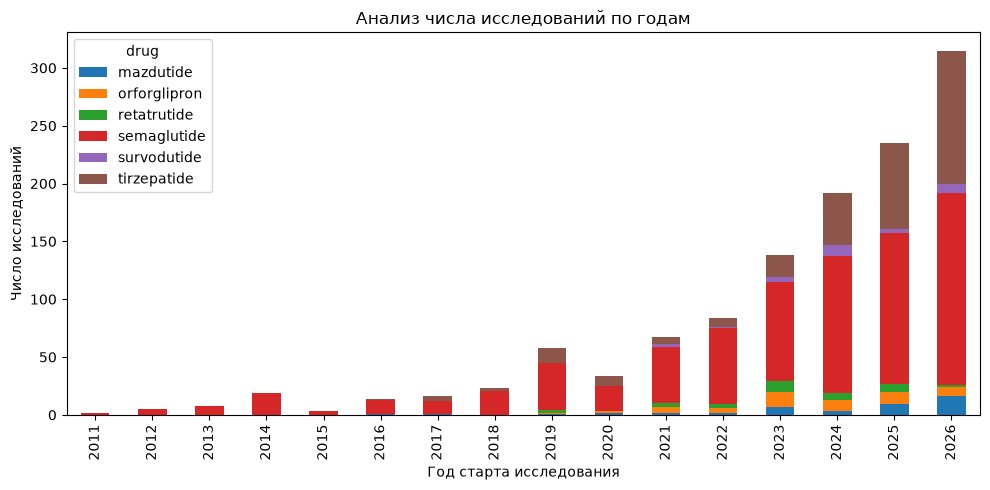

In [77]:
d = df[df["status"] != "WITHDRAWN"].dropna(subset=["start_year"]).copy()
d["start_year"] = d["start_year"].astype(int)
d = d[(d["start_year"] >= 2010) & (d["start_year"] <= 2026)]
len(d)


by_year = pd.crosstab(d["start_year"], d["drug"])
by_year


by_year.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Анализ числа исследований по годам")
plt.xlabel("Год старта исследования")
plt.ylabel("Число исследований")
plt.tight_layout()
plt.savefig("../figures/01_trials_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

Большая часть исследований появились уже с 2021 года, хоть и в 2019 был небольшой скачок, в основном за счёт добавления исследований по другим препаратам. До 2019 исследований не по Semaglutide практически не было, большая часть исследований за всё время именно по Semaglutide и Tirzepatide. 

In [78]:
total = len(d)
print((d["start_year"] >= 2021).sum() / total)           # доля исследований с 2021 года
print(d["drug"].value_counts(normalize=True))             # доля препаратов

0.8499587798845837
drug
semaglutide     0.625721
tirzepatide     0.244023
orforglipron    0.043693
mazdutide       0.036274
retatrutide     0.026381
survodutide     0.023908
Name: proportion, dtype: float64


Итог: около 85% исследований стартовали с 2021 года. Semaglutide (62,6%) и tirzepatide (24,4%) дают около 87% всей активности, остальные четыре препарата вместе около 13%.

### Но в каких именно областях растёт применение антагонистов GLP-1/GIP/GCGR?

In [79]:
cats = {
    "diabetes": ["diabet"],
    "obesity": ["obes", "overweight", "weight"],
    "liver": ["nash", "mash", "steatohep", "liver", "hepat"],
    "cardio": ["cardio", "heart", "hypertens"],
    "kidney": ["kidney", "renal", "nephro"],
    "healthy": ['healthy']
}
low = d["conditions"].str.lower()
for k, words in cats.items():
    d[k] = low.str.contains("|".join(words), na=False)
d["other"] = ~d[list(cats)].any(axis=1)

In [80]:
cols = list(cats) + ["other"]
print(d[cols].sum().sort_values(ascending=False))
print()
print(d[d["other"]]["conditions"].str.split("; ").explode().value_counts().head(20))
print()
print(len(d))

obesity     587
diabetes    495
other       145
healthy      92
cardio       78
liver        60
kidney       48
dtype: int64

conditions
Alcohol Use Disorder                       9
Endometrial Cancer                         4
Gastric Retention                          4
Endometrioid Endometrial Adenocarcinoma    3
Metabolic Syndrome                         3
Semaglutide                                3
Opioid Use Disorder                        3
Acute Ischemic Stroke                      3
T2DM                                       3
Alcohol Use Disorder (AUD)                 3
Polycystic Ovary Syndrome                  2
Alzheimer Disease                          2
GLP-1                                      2
Aging                                      2
Semaglutide-Induced Gastric Motility       2
Anesthesia                                 2
Psoriasis                                  2
Caloric Restriction                        2
Body Composition                           2
Performa

Ожирение и диабет занимают основу исследований, а кардио, печень и почки пока составляют небольшую долю.

Сумма больше 1213, потому что одно исследование может быть сразу в двух категориях, например в диабете и ожирении.

In [81]:
by_cat_year = d.groupby("start_year")[cols].sum()
by_cat_year.loc[2018:]

by_cat_drug = d.groupby("drug")[cols].sum()
by_cat_drug

,diabetes,obesity,liver,cardio,kidney,healthy,other
drug,,,,,,,
mazdutide,13,24,5,4,2,2,2
orforglipron,16,23,1,6,3,17,4
retatrutide,10,16,2,2,2,6,0
semaglutide,369,320,35,42,33,48,99
survodutide,2,19,6,0,2,9,0
tirzepatide,85,185,11,24,6,10,40


In [82]:
by_cat_drug.div(d.groupby("drug").size(), axis=0).round(2)

cols = list(cats) + ["other"]
counts = d.groupby("drug")[cols].sum()
share = counts.div(d.groupby("drug").size(), axis=0)
share = share.loc[d["drug"].value_counts().index]
print(share.round(2))

              diabetes  obesity  liver  cardio  kidney  healthy  other
drug                                                                  
semaglutide       0.49     0.42   0.05    0.06    0.04     0.06   0.13
tirzepatide       0.29     0.62   0.04    0.08    0.02     0.03   0.14
orforglipron      0.30     0.43   0.02    0.11    0.06     0.32   0.08
mazdutide         0.30     0.55   0.11    0.09    0.05     0.05   0.05
retatrutide       0.31     0.50   0.06    0.06    0.06     0.19   0.00
survodutide       0.07     0.66   0.21    0.00    0.07     0.31   0.00


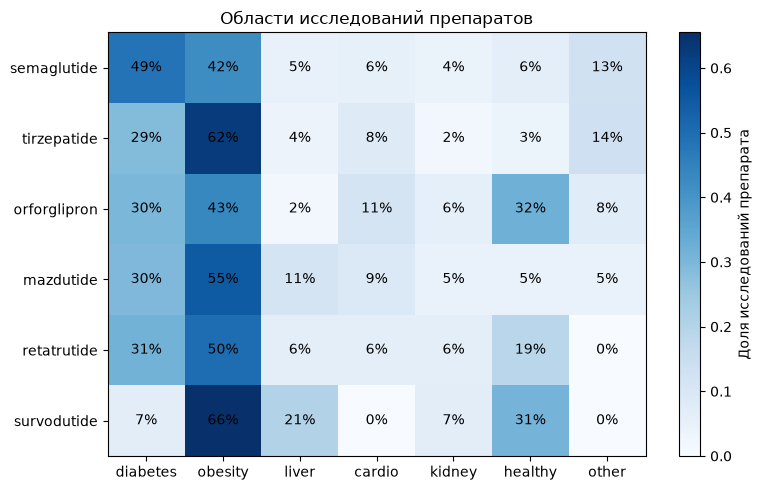

In [83]:
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(share.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(share.columns)))
ax.set_xticklabels(share.columns)
ax.set_yticks(range(len(share.index)))
ax.set_yticklabels(share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, f"{share.iloc[i, j]:.0%}", ha="center", va="center")
fig.colorbar(im, label="Доля исследований препарата")
ax.set_title("Области исследований препаратов")  # вывод, а не описание
plt.tight_layout()
plt.savefig("../figures/03_indication_profile.png", dpi=200, bbox_inches="tight")
plt.show()

Профили показаний различаются. 

Semaglutide остаётся единственным препаратом, у которого диабет (49%) преобладает над ожирением (42%). 

У tirzepatide (62%), survodutide (66%) и mazdutide (55%) ожирение занимает больше половины исследований, у retatrutide оно составляет ровно половину (50%). 

Печень заметна у survodutide (21%) и mazdutide (11%), у остальных не выше 6%. Survodutide выделяется печёночным направлением: 6 исследований, из них 5 посвящены MASH/NASH и 4 находятся в фазе 3. 
Кардио максимально у orforglipron (11%) и mazdutide (9%), почки не выше 7%. 

У orforglipron (32%), survodutide (31%) и retatrutide (19%) велика доля исследований на здоровых добровольцах, что говорит о ранней стадии разработки.

> * Категории пересекаются, одно исследование может быть и в диабете, и в ожирении, поэтому строки в сумме дают больше 100%.

In [84]:
print(d[(d["drug"] == "survodutide") & d["liver"]][["title", "conditions", "phase"]])

                                                 title  \
923  A Study to (1) Compare How BI 456906 is Taken ...   
929  LIVERAGE™: A Study to Test Whether Survodutide...   
933  ELEVATE-LIVER: A Study to Test Whether Survodu...   
943  A Study to Test Safety and Efficacy of Survodu...   
946  LIVERAGE™ - Cirrhosis: A Study to Test Whether...   
947  A Study to Test Whether Survodutide Helps Peop...   

                                            conditions   phase  
923                   Healthy; Liver Diseases; Obesity  PHASE1  
929  Metabolic Dysfunction Associated Steatohepatit...  PHASE3  
933  Obesity; Metabolic Dysfunction-associated Stea...  PHASE3  
943               Non-alcoholic Steatohepatitis (NASH)  PHASE2  
946   Metabolic Dysfunction Associated Steatohepatitis  PHASE3  
947      Obesity; Non-Alcoholic SteatoHepatitis (NASH)  PHASE3  


### Далее следует оценить динамику показаний по годам, чтобы понять, растёт ли количество исследований по печени и кардио:


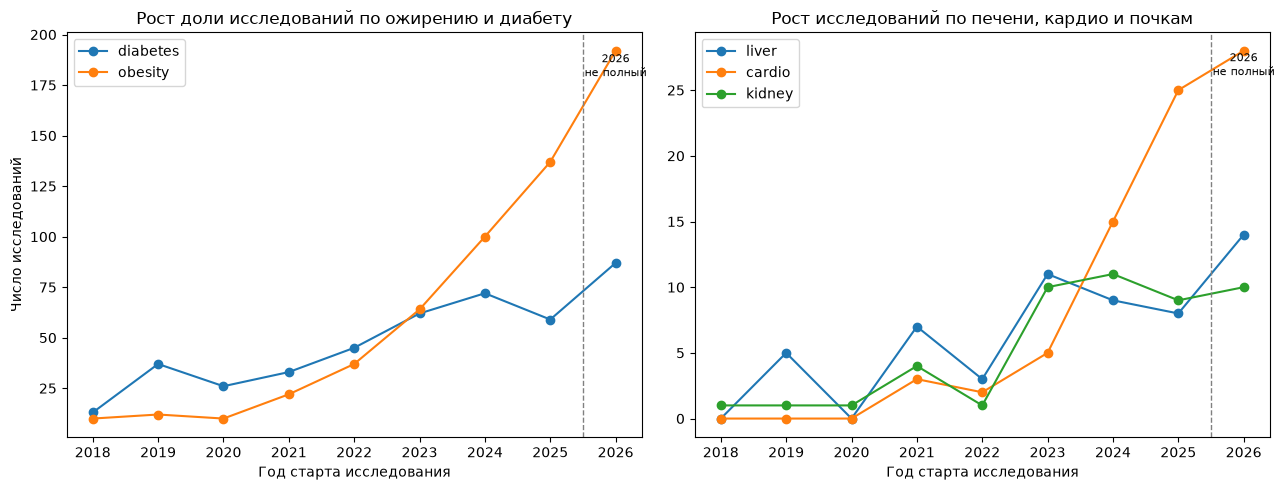

In [85]:
cols = list(cats)  # diabetes, obesity, liver, cardio, kidney, healthy
cat_year = d.groupby("start_year")[cols].sum().loc[2018:]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

main = ["diabetes", "obesity"]
for c in main:
    axes[0].plot(cat_year.index, cat_year[c], marker="o", label=c)
axes[0].set_title("Рост доли исследований по ожирению и диабету")  # вывод по диабету и ожирению
axes[0].set_xlabel("Год старта исследования")
axes[0].set_ylabel("Число исследований")
axes[0].legend()

small = ["liver", "cardio", "kidney"]
for c in small:
    axes[1].plot(cat_year.index, cat_year[c], marker="o", label=c)
axes[1].set_title("Рост исследований по печени, кардио и почкам")  # вывод по печени, кардио, почкам
axes[1].set_xlabel("Год старта исследования")
axes[1].legend()

for ax in axes:
    ax.axvline(2025.5, color="gray", linestyle="--", linewidth=1)
    ax.text(2026, ax.get_ylim()[1] * 0.95, "2026\nне полный", ha="center", va="top", fontsize=8)

plt.tight_layout()
plt.savefig("../figures/02_indications_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

In [86]:
tot = d.groupby("start_year").size().loc[2018:]
share_year = cat_year.div(tot, axis=0)
print(share_year[["obesity", "cardio", "liver", "kidney"]].round(2))

            obesity  cardio  liver  kidney
start_year                                
2018           0.43    0.00   0.00    0.04
2019           0.21    0.00   0.09    0.02
2020           0.29    0.00   0.00    0.03
2021           0.33    0.04   0.10    0.06
2022           0.44    0.02   0.04    0.01
2023           0.46    0.04   0.08    0.07
2024           0.52    0.08   0.05    0.06
2025           0.58    0.11   0.03    0.04
2026           0.61    0.09   0.04    0.03


In [87]:
print((d["cardio"] & d["obesity"]).sum(), d["cardio"].sum())

40 78


По видимому, 40 из 79 исследований по кардио (около 51%) относятся и к ожирению. Значит, примерно половина кардио-активности возникает внутри ожирения, а вторая половина идёт отдельно (например, в диабете или при болезнях сердца без акцента на вес).

In [88]:
d["phase_max"] = (
    d["phase"].str.findall(r"PHASE(\d)")
    .apply(lambda x: max(x) if isinstance(x, list) and x else None)
)
tab = pd.crosstab(d["drug"], d["phase_max"], normalize="index").round(2)
n = d.dropna(subset=["phase_max"]).groupby("drug").size()
print(tab)
print()
print(n)

phase_max        1     2     3     4
drug                                
mazdutide     0.19  0.36  0.31  0.14
orforglipron  0.40  0.06  0.51  0.04
retatrutide   0.44  0.12  0.44  0.00
semaglutide   0.22  0.23  0.33  0.22
survodutide   0.48  0.10  0.41  0.00
tirzepatide   0.18  0.33  0.27  0.22

drug
mazdutide        36
orforglipron     53
retatrutide      32
semaglutide     542
survodutide      29
tirzepatide     218
dtype: int64


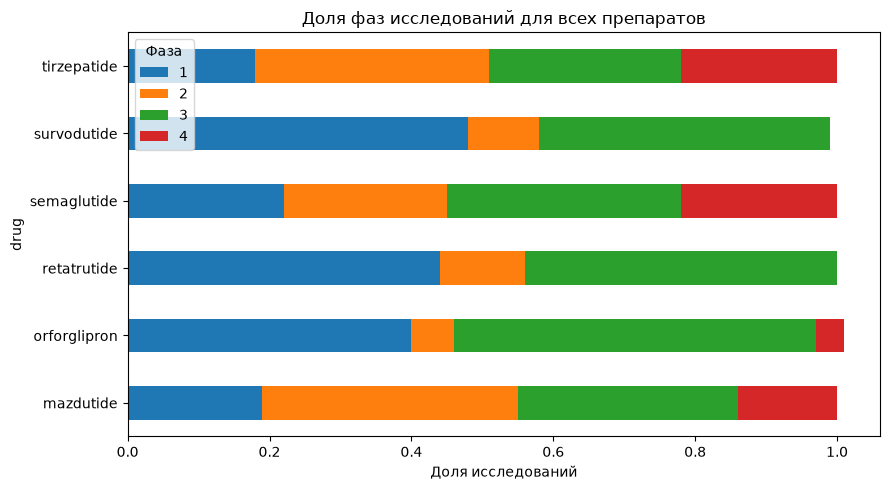

In [89]:
tab.plot(kind="barh", stacked=True, figsize=(9, 5))
plt.xlabel("Доля исследований")
plt.title("Доля фаз исследований для всех препаратов")  # вывод
plt.legend(title="Фаза")
plt.tight_layout()
plt.savefig("../figures/04_phases_by_drug.png", dpi=200, bbox_inches="tight")

Фаза 4 (применение после выхода на рынок) занимает по 22% у semaglutide и tirzepatide. У остальных четырёх она не превышает 14%. Среди новых молекул самая высокая доли фазы 3 у orforglipron (51%). У survodutide и retatrutide почти половина исследований пока в фазе 1 (48% и 44%).

В общем, у новых молекул преобладают фазы 1 и 3.

In [90]:
print(d["sponsor"].value_counts().head(10))
print()
print(d.groupby("drug")["sponsor"].agg(lambda s: s.value_counts().head(2).to_dict()))

sponsor
Novo Nordisk A/S                        258
Eli Lilly and Company                   178
Boehringer Ingelheim                     34
Brigham and Women's Hospital             29
Innovent Biologics (Suzhou) Co. Ltd.     23
University of Colorado, Denver           14
The Cleveland Clinic                     12
Mayo Clinic                              10
Vanderbilt University Medical Center      8
University Medical Centre Ljubljana       8
Name: count, dtype: int64

drug
mazdutide       {'Innovent Biologics (Suzhou) Co. Ltd.': 19, '...
orforglipron    {'Eli Lilly and Company': 49, 'Massachusetts G...
retatrutide     {'Eli Lilly and Company': 31, 'Hudson Biotech'...
semaglutide     {'Novo Nordisk A/S': 252, 'Brigham and Women's...
survodutide     {'Boehringer Ingelheim': 28, 'University Medic...
tirzepatide     {'Eli Lilly and Company': 81, 'Brigham and Wom...
Name: sponsor, dtype: object


In [91]:
top = d.groupby("drug")["sponsor"].agg(
    lead=lambda s: s.value_counts().index[0],
    lead_n=lambda s: s.value_counts().iloc[0],
    n="size",
)
top["lead_share"] = (top["lead_n"] / top["n"]).round(2)
print(top)

                                              lead  lead_n    n  lead_share
drug                                                                       
mazdutide     Innovent Biologics (Suzhou) Co. Ltd.      19   44        0.43
orforglipron                 Eli Lilly and Company      49   53        0.92
retatrutide                  Eli Lilly and Company      31   32        0.97
semaglutide                       Novo Nordisk A/S     252  759        0.33
survodutide                   Boehringer Ingelheim      28   29        0.97
tirzepatide                  Eli Lilly and Company      81  296        0.27


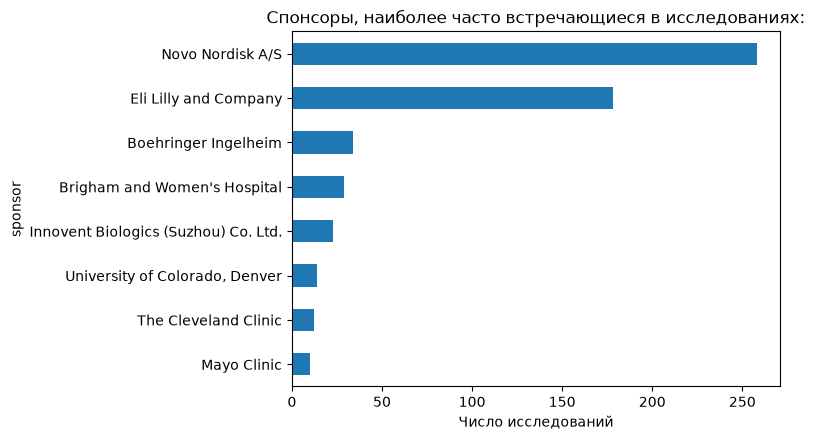

In [92]:
top8 = d["sponsor"].value_counts().head(8).sort_values()
top8.plot(kind="barh", figsize=(8, 4.5))
plt.xlabel("Число исследований")
plt.title("Спонсоры, наиболее часто встречающиеся в исследованиях:")  # вывод
plt.tight_layout()
plt.savefig("../figures/05_top_sponsors.png", dpi=200, bbox_inches="tight")

По спонсорам новые молекулы почти целиком принадлежат своим разработчикам: retatrutide (97%) и orforglipron (92%) у Eli Lilly, survodutide (97%) у Boehringer Ingelheim. У mazdutide ведущий спонсор Innovent Biologics занимает 43% исследований, то есть в программе участвует много других организаций. У зрелых препаратов доля ведущей компании ниже: semaglutide 33% (252 из 759), tirzepatide 27% (81 из 296). 

Остальное в основном исследования академических и клинических центров, которые запускают собственные работы, когда препарат уже доступен.